In [1]:
from datasets import load_dataset

ds = load_dataset("naver-clova-ix/cord-v2", cache_dir="../data")
print(ds)

c:\dev\receipt-extraction-benchmark\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating test split: 100%|██████████| 100/100 [00:00<00:00, 182.13 examples/s]


DatasetDict({
    train: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 800
    })
    validation: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 100
    })
    test: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 100
    })
})


dict_keys(['image', 'ground_truth'])
{
  "menu": [
    {
      "nm": "Nasi Campur Bali",
      "cnt": "1 x",
      "price": "75,000"
    },
    {
      "nm": "Bbk Bengil Nasi",
      "cnt": "1 x",
      "price": "125,000"
    },
    {
      "nm": "MilkShake Starwb",
      "cnt": "1 x",
      "price": "37,000"
    },
    {
      "nm": "Ice Lemon Tea",
      "cnt": "1 x",
      "price": "24,000"
    },
    {
      "nm": "Nasi Ayam Dewata",
      "cnt": "1 x",
      "price": "70,000"
    },
    {
      "nm": "Free Ice Tea",
      "cnt": "3 x",
      "price": "0"
    },
    {
      "nm": "Organic Green Sa",
      "cnt": "1 x",
      "price": "65,000"
    },
    {
      "nm": "Ice Tea",
      "cnt": "1 x",
      "price": "18,000"
    },
    {
      "nm": "Ice Orange",
      "cnt": "1 x",
      "price": "29,000"
    },
    {
      "nm": "Ayam Suir Bali",
      "cnt": "1 x",
      "price": "85,000"
    },
    {
      "nm": "Tahu Goreng",
      "cnt": "2 x",
      "price": "36,000"
    },
    

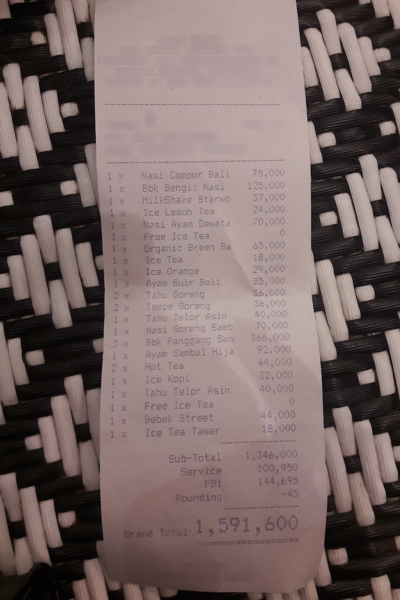

In [2]:
import json

sample = ds["train"][0]
print(sample.keys())

gt = json.loads(sample["ground_truth"])
print(json.dumps(gt["gt_parse"], indent=2, ensure_ascii=False))

img = sample["image"].copy()
img.thumbnail((600, 600))
img

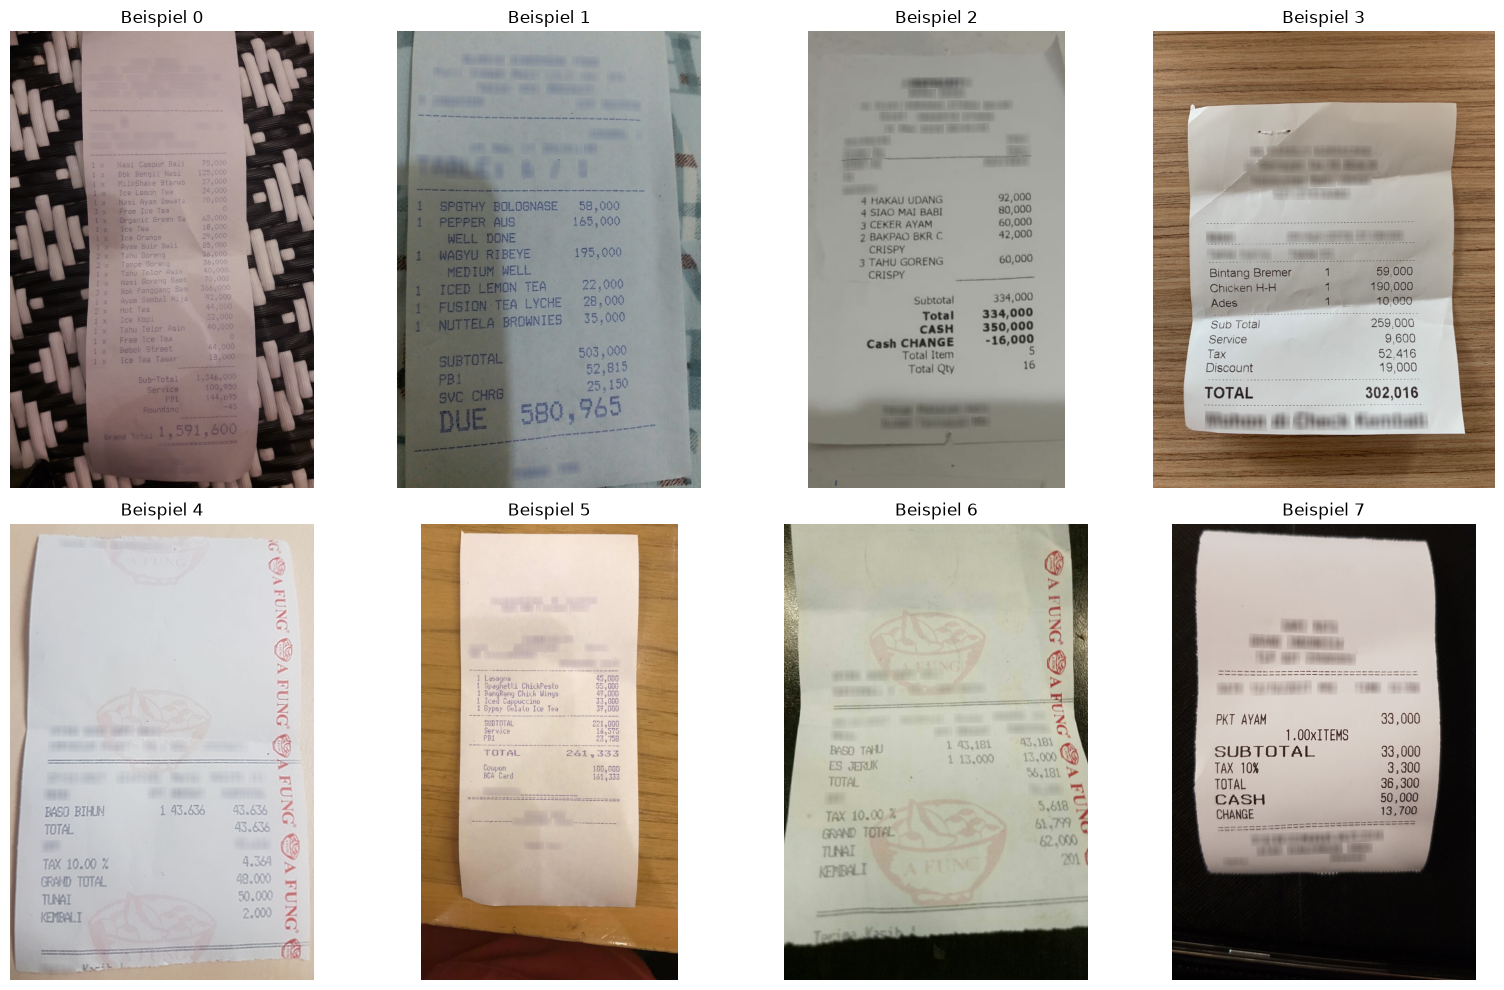

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 10))
for i, ax in enumerate(axes.flat):
    ax.imshow(ds["train"][i]["image"])
    ax.set_title(f"Beispiel {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
from collections import Counter

counter = Counter()
for gt_string in ds["train"]["ground_truth"]:
    gt = json.loads(gt_string)["gt_parse"]
    for key, value in gt.items():
        if isinstance(value, dict):
            for subkey in value:
                counter[f"{key}.{subkey}"] += 1
        else:
            counter[key] += 1

n = len(ds["train"])
for field, count in counter.most_common():
    print(f"{field:30s} {count:4d}  ({count / n:.0%})")

total.total_price               779  (97%)
sub_total.subtotal_price        529  (66%)
total.cashprice                 517  (65%)
total.changeprice               500  (62%)
menu                            454  (57%)
sub_total.tax_price             354  (44%)
menu.price                      345  (43%)
menu.nm                         342  (43%)
menu.cnt                        312  (39%)
total.menuqty_cnt               228  (28%)
menu.unitprice                  126  (16%)
total.creditcardprice           121  (15%)
sub_total.service_price          98  (12%)
sub_total.etc                    68  (8%)
menu.sub                         68  (8%)
sub_total.discount_price         61  (8%)
total.emoneyprice                46  (6%)
total.menutype_cnt               42  (5%)
total.total_etc                  26  (3%)
menu.num                         17  (2%)
menu.discountprice                7  (1%)
menu.vatyn                        2  (0%)
void_menu.nm                      1  (0%)
void_menu.price      